In [1]:
import pandas as pd
import numpy as np
from scipy import stats
import ast

from sklearn import metrics
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import matthews_corrcoef
from sklearn.metrics import roc_curve, roc_auc_score


import matplotlib.pyplot as plt


In [2]:
def classification_metrics(target, pred):
    tn, fp, fn, tp = metrics.confusion_matrix(target, pred).ravel()
    acc = (tp + tn) / (tn + fp + fn + tp)
    sen = tp / (tp + fn)
    spc = tn / (tn + fp)
    prc = tp / (tp + fp)
    mcc = ((tp * tn) - (fp * fn)) / ((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn) + .00000001) ** 0.5
    return acc.item(), sen.item(), spc.item(), prc.item(), mcc.item()

# acc, sen, spc, prc, mcc = classification_metrics(y_test, y_hat)

In [67]:
df_dock = pd.read_csv("data/Result_smina_18may.csv")
# df_dock = df_dock[['Protein', 'Ligand', 'Affinity', 'Pose_num']]
df_dock['ID'] = [i.split('_')[0] for i in df_dock['Ligand']]
df_dock = df_dock.groupby('ID').aggregate('min')
# df_dock['ID'] = df_dock.index
df_dock.head()

,Unnamed: 0,Protein,Ligand,Affinity,Pose_num,Ligand_pdb
ID,,,,,,
CSCS00000001360,0,PAH_6N1K,CSCS00000001360_0,-7.718688,0,../data/screen_8000/result/dock_smina_PAH_6N1K...
CSCS00000002301,0,PAH_6N1K,CSCS00000002301_0,-8.003690,0,../data/screen_8000/result/dock_smina_PAH_6N1K...
CSCS00000007163,0,PAH_6N1K,CSCS00000007163_0,-7.980068,0,../data/screen_8000/result/dock_smina_PAH_6N1K...
CSCS00000008923,0,PAH_6N1K,CSCS00000008923_0,-6.757397,0,../data/screen_8000/result/dock_smina_PAH_6N1K...
CSCS00000010642,0,PAH_6N1K,CSCS00000010642_0,-7.084342,0,../data/screen_8000/result/dock_smina_PAH_6N1K...


In [69]:
set([i.split('_')[2] for i in df_dock['Ligand_pdb']])

{'smina'}

In [30]:
control_ligands = [i for i in df_dock.index if i.find('CSCS') == -1]
control_affinity = df_dock.loc[df_dock.index.isin(control_ligands), 'Affinity'].tolist()
control_ligands, control_affinity

(['UCR102'], [-9.0906601])

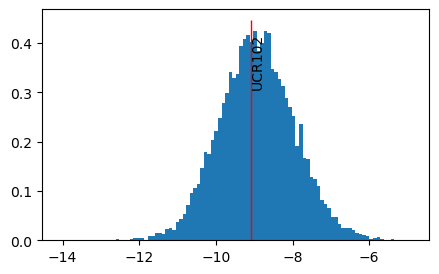

In [31]:
plt.figure(figsize=(5, 3))

plt.hist(df_dock['Affinity'], 100, density=True);
y_max = plt.ylim()[1]
plt.vlines(control_affinity, ymin=0, ymax=y_max, color='red', linewidth = 1);
for lig, aff in zip(control_ligands, control_affinity):
    plt.text(x=aff, y=y_max*.7, s=lig, rotation = 90, size = 10)

# plt.xlim([-8, 0]);

In [32]:
# plt.figure(figsize=(5, 3))

# plt.hist(df_dock['docking score'], 100, density=True);
# y_max = plt.ylim()[1]
# plt.vlines(control_affinity, ymin=0, ymax=y_max, color='red', linewidth = 1);
# for lig, aff in zip(control_ligands, control_affinity):
#     plt.text(x=aff, y=y_max*.7, s=lig, rotation = 90, size = 10)
# plt.xlim([-7, -3.6]);

In [50]:
col_bind = 'Binding_validated_by_TSA'
protein = 'PAH-WT'
# col_bind = 'new'

df_expr = pd.read_csv("data/PO_norm_outlier_removed.csv")
# df_expr = pd.read_csv("data/PO_norm_analysed_16may.csv")

df_expr['bind_tsa'] = df_expr['bind_tsa'].apply(ast.literal_eval)
# df_expr[col_bind] = df_expr['bind_tsa'].map(conversion_dict)

df_expr = df_expr[['ID', 'Protein', col_bind]]
df_expr = df_expr.loc[~df_expr['ID'].isin(['BH4', 'UCR243', 'UCR102'])]
df_expr = df_expr.loc[df_expr['Protein'] == protein]
df_expr.head()

,ID,Protein,Binding_validated_by_TSA
2,CSCS00027898135,PAH-WT,no_evidence
3,CSCS00027264039,PAH-WT,no_evidence
4,CSCS00027379165,PAH-WT,weak_evidence
5,CSCS00028338246,PAH-WT,weak_evidence
6,CSCS00027378562,PAH-WT,no_evidence


In [51]:
df_merge = pd.merge(df_expr, df_dock, on = 'ID')
df_merge = df_merge.loc[df_merge[col_bind] != 'weak_evidence']
df_merge.head()

,ID,Protein_x,Binding_validated_by_TSA,Protein_y,Ligand,Affinity,Pose_num
0,CSCS00027898135,PAH-WT,no_evidence,PAH_6N1K,CSCS00027898135_0,-9.540176,0
1,CSCS00027264039,PAH-WT,no_evidence,PAH_6N1K,CSCS00027264039_0,-6.771367,0
4,CSCS00027378562,PAH-WT,no_evidence,PAH_6N1K,CSCS00027378562_0,-7.900095,0
5,CSCS00028232463,PAH-WT,no_evidence,PAH_6N1K,CSCS00028232463_0,-9.479123,0
6,CSCS00027378343,PAH-WT,no_evidence,PAH_6N1K,CSCS00027378343_0,-8.156437,0


In [52]:
df_merge.loc[df_merge['Binding_validated_by_TSA'] == 'strong_evidence', 'Affinity'].mean()

np.float64(-9.043203556441718)

In [53]:
df_merge.loc[df_merge['Binding_validated_by_TSA'] == 'no_evidence', 'Affinity'].mean()

np.float64(-8.732607879973754)

In [54]:
df_merge.loc[df_merge['Binding_validated_by_TSA'] == 'weak_evidence', 'Affinity'].mean()

nan

In [55]:
tab = df_merge.groupby(col_bind).size()
tab

Binding_validated_by_TSA
no_evidence        381
strong_evidence    163
dtype: int64

In [56]:
hit_ratio = (tab['strong_evidence'] / tab.sum()).item()
hit_ratio

0.29963235294117646

In [57]:
score = df_merge['Affinity']
target = df_merge[col_bind] == 'strong_evidence'
total_pos = target.sum().item()
prc_chance = hit_ratio

In [64]:
percentage_set = [5, 10, 15, 20, 25, 30, 35, 40, 45, 50, 60, 70, 80, hit_ratio*100]
percentage_set.sort()
df_result = pd.DataFrame(columns=['percentage', 'acc', 'sen', 'spc', 'prc', 'mcc', 'best_sen', 'sen_chance', 'best_prc', 'prc_chance'])

for percentage in percentage_set:
    # Obtain target and pred
    threshold = np.percentile(score, percentage)
    pred = score < threshold
    # Calculate best sen and prc
    top_k = pred.sum().item()
    sen_best = min(1, top_k / total_pos)
    prc_best = min(1, total_pos / top_k)
    sen_chance = percentage / 100
    # Calculate measures
    acc, sen, spc, prc, mcc = classification_metrics(target, pred)
    df_result.loc[len(df_result)] = [percentage, acc, sen, spc, prc, mcc, sen_best, sen_chance, prc_best, prc_chance]

df_result

,percentage,acc,sen,spc,prc,mcc,best_sen,sen_chance,best_prc,prc_chance
0,5.000000,0.685662,0.061350,0.952756,0.357143,0.029244,0.171779,0.050000,1.000000,0.299632
1,10.000000,0.669118,0.116564,0.905512,0.345455,0.033546,0.337423,0.100000,1.000000,0.299632
2,15.000000,0.645221,0.159509,0.853018,0.317073,0.016040,0.503067,0.150000,1.000000,0.299632
3,20.000000,0.639706,0.233129,0.813648,0.348624,0.053534,0.668712,0.200000,1.000000,0.299632
4,25.000000,0.608456,0.263804,0.755906,0.316176,0.020851,0.834356,0.250000,1.000000,0.299632
5,29.963235,0.588235,0.312883,0.706037,0.312883,0.018920,1.000000,0.299632,1.000000,0.299632
6,30.000000,0.588235,0.312883,0.706037,0.312883,0.018920,1.000000,0.300000,1.000000,0.299632
7,35.000000,0.580882,0.386503,0.664042,0.329843,0.048510,1.000000,0.350000,0.853403,0.299632
8,40.000000,0.568015,0.447853,0.619423,0.334862,0.062889,1.000000,0.400000,0.747706,0.299632
9,45.000000,0.569853,0.533742,0.585302,0.355102,0.109609,1.000000,0.450000,0.665306,0.299632


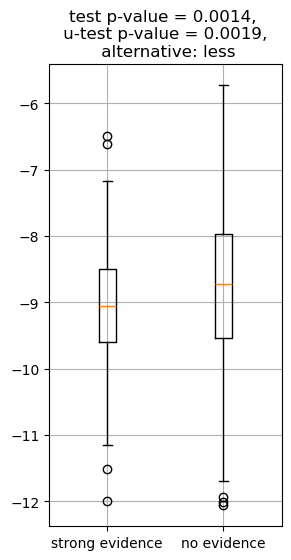

In [65]:
# Calculate p-value and boxplot
plt.figure(figsize=(3, 6))
pval_ttest = stats.ttest_ind(score[target], 
                        score[~target],
                        alternative='less',
                          ).pvalue.item()
pval_utest = stats.mannwhitneyu(score[target], 
                           score[~target],
                           alternative='less',
                          ).pvalue.item()
plt.boxplot([score[target], score[~target]]);
plt.grid()
plt.title(f'test p-value = {pval_ttest:.4f}, \n u-test p-value = {pval_utest:.4f}, \n alternative: less')
plt.xticks([1, 2], ['strong evidence', 'no evidence']);

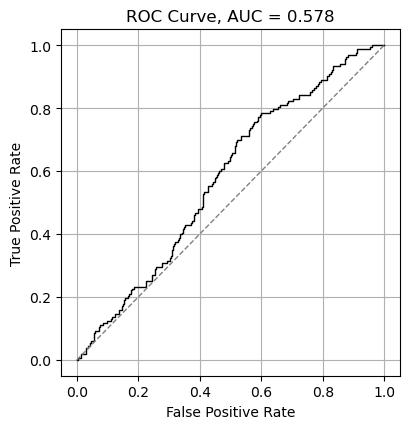

np.float64(0.5781685264802022)

In [66]:
auc_score = roc_auc_score(target, -score)
fpr, tpr, thresholds = roc_curve(target, -score)

plt.figure(figsize=(4, 4))

plt.plot(fpr, tpr, label=f'AUC = {auc_score:.3f}', color = 'black', linewidth=1)
plt.plot([0, 1], [0, 1], '--', label='Random', color='gray', linewidth=1)
plt.grid(True)
plt.tight_layout()

plt.title(f'ROC Curve, AUC = {np.mean(auc_score):.3f}')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.show()

auc_score